# Experiment No. 9 — Data Storytelling and Business Insight Generation using Interactive Visualizations



## Step 3: Exploratory analysis to surface trends, patterns, and anomalies

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('superstore.csv', encoding='latin1')
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Order Year'] = df['Order Date'].dt.year

print("Shape:", df.shape)
df.head()


Shape: (10800, 22)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year
0,1,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017.0
1,2,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017.0
2,3,CA-2017-138688,2017-06-12,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017.0
3,4,US-2016-108966,2016-10-11,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016.0
4,5,US-2016-108966,2016-10-11,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016.0


## Step 4 & 5: KPIs — the headline numbers for the story

In [ ]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
overall_margin = total_profit / total_sales * 100
yearly = df.groupby('Order Year')[['Sales','Profit']].sum()
yearly['Margin %'] = yearly['Profit'] / yearly['Sales'] * 100

print(f"Total Sales:  ${total_sales:,.0f}")
print(f"Total Profit: ${total_profit:,.0f}")
print(f"Overall Profit Margin: {overall_margin:.1f}%")
print()
print(yearly.round(1))


Total Sales:  $2,297,201
Total Profit: $286,397
Overall Profit Margin: 12.5%

               Sales   Profit  Margin %
Order Year                             
2015.0      484247.5  49544.0      10.2
2016.0      470532.5  61618.6      13.1
2017.0      609205.6  81795.2      13.4
2018.0      733215.3  93439.3      12.7


## Chapter 1 — Sales are growing

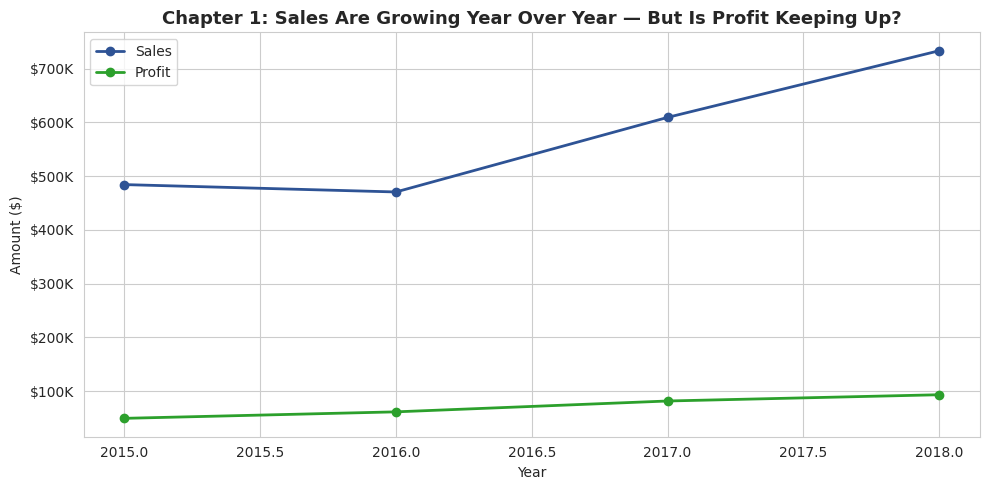

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(yearly.index, yearly['Sales'], marker='o', linewidth=2, color='#2E5395', label='Sales')
plt.plot(yearly.index, yearly['Profit'], marker='o', linewidth=2, color='#2ca02c', label='Profit')
plt.title('Chapter 1: Sales Are Growing Year Over Year — But Is Profit Keeping Up?', fontsize=13, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Amount ($)')
plt.gca().yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:,.0f}K'))
plt.legend()
plt.tight_layout()
plt.savefig('story_ch1_growth.png', dpi=120)
plt.show()


**Narrative:** Sales climb every year, but the Profit line grows much more slowly and flattens
in places — a visible gap that sets up the central question of the story: what's eating into
margin even as revenue rises?

## Chapter 2 — Where the problem lives: Category and Region

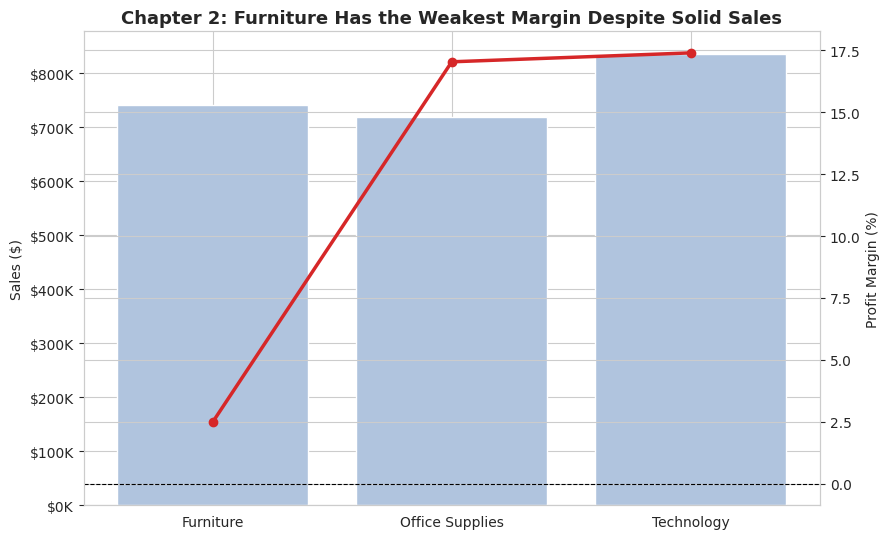

,Sales,Profit,Margin %
Category,,,
Furniture,741999.8,18451.3,2.5
Office Supplies,719047.0,122490.8,17.0
Technology,836154.0,145454.9,17.4


In [ ]:
cat_perf = df.groupby('Category')[['Sales','Profit']].sum()
cat_perf['Margin %'] = cat_perf['Profit'] / cat_perf['Sales'] * 100

fig, ax1 = plt.subplots(figsize=(9,5.5))
ax1.bar(cat_perf.index, cat_perf['Sales'], color='#B0C4DE', label='Sales')
ax1.set_ylabel('Sales ($)')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:,.0f}K'))

ax2 = ax1.twinx()
ax2.plot(cat_perf.index, cat_perf['Margin %'], color='#d62728', marker='o', linewidth=2.5, label='Profit Margin %')
ax2.set_ylabel('Profit Margin (%)')
ax2.axhline(0, color='black', linewidth=0.8, linestyle='--')

plt.title('Chapter 2: Furniture Has the Weakest Margin Despite Solid Sales', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.savefig('story_ch2_category.png', dpi=120)
plt.show()
cat_perf.round(1)


**Narrative:** Furniture generates meaningful sales but the thinnest margin of the three
categories by far — the first concrete clue pointing toward where the profit problem is
concentrated.

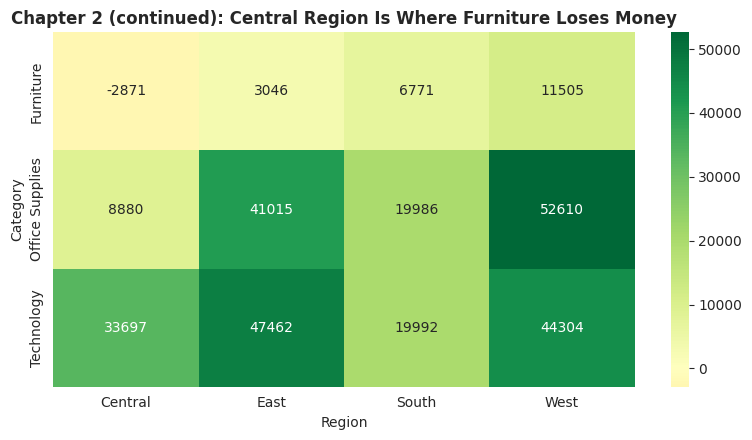

In [ ]:
region_cat = df.pivot_table(values='Profit', index='Category', columns='Region', aggfunc='sum')

plt.figure(figsize=(8,4.5))
sns.heatmap(region_cat, annot=True, fmt='.0f', cmap='RdYlGn', center=0)
plt.title('Chapter 2 (continued): Central Region Is Where Furniture Loses Money', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('story_ch2_heatmap.png', dpi=120)
plt.show()


**Narrative:** Narrowing further, the Category x Region view shows the weak Furniture margin
is not evenly spread — it is heavily concentrated in the Central region, turning a category-level
observation into a specific, addressable business problem.

## Chapter 3 — The root cause: discounting

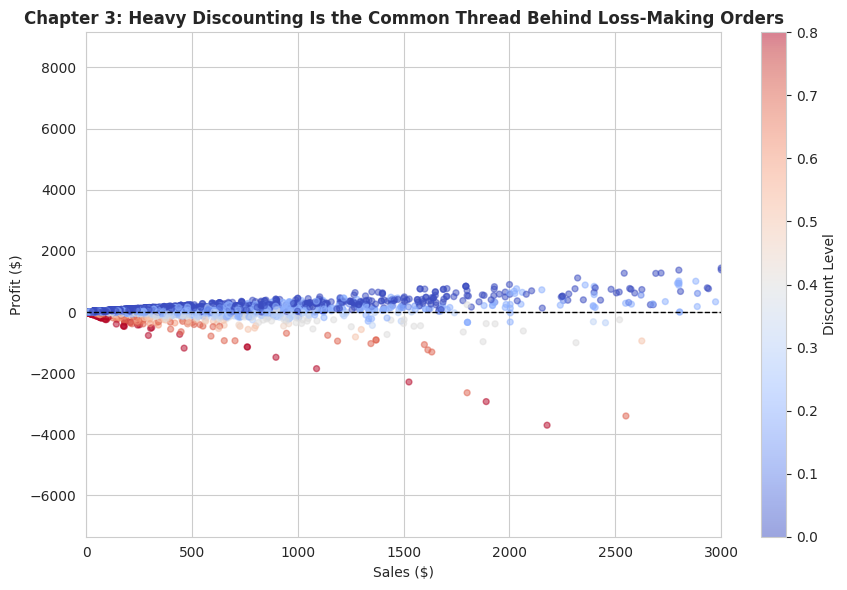

Sales       0.479064
Discount   -0.219487
Profit      1.000000
Name: Profit, dtype: float64


In [ ]:
plt.figure(figsize=(9,6))
scatter = plt.scatter(df['Sales'], df['Profit'], c=df['Discount'], cmap='coolwarm', alpha=0.5, s=18)
plt.colorbar(scatter, label='Discount Level')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.xlim(0, 3000)
plt.title('Chapter 3: Heavy Discounting Is the Common Thread Behind Loss-Making Orders', fontsize=12, fontweight='bold')
plt.xlabel('Sales ($)')
plt.ylabel('Profit ($)')
plt.tight_layout()
plt.savefig('story_ch3_rootcause.png', dpi=120)
plt.show()

corr = df[['Sales','Discount','Profit']].corr()['Profit']
print(corr)


**Narrative:** The scatter plot reveals the root cause: high-discount orders (warm colors)
sit almost exclusively in the loss-making region of the chart, regardless of sales size. The
correlation confirms it numerically — Discount has a clear negative relationship with Profit,
while Sales alone barely matters. The story's climax: **it isn't sales volume causing weak
margins, it's how much is being discounted to get those sales.**

## Chapter 4 — Seasonality: when the problem is most exposed

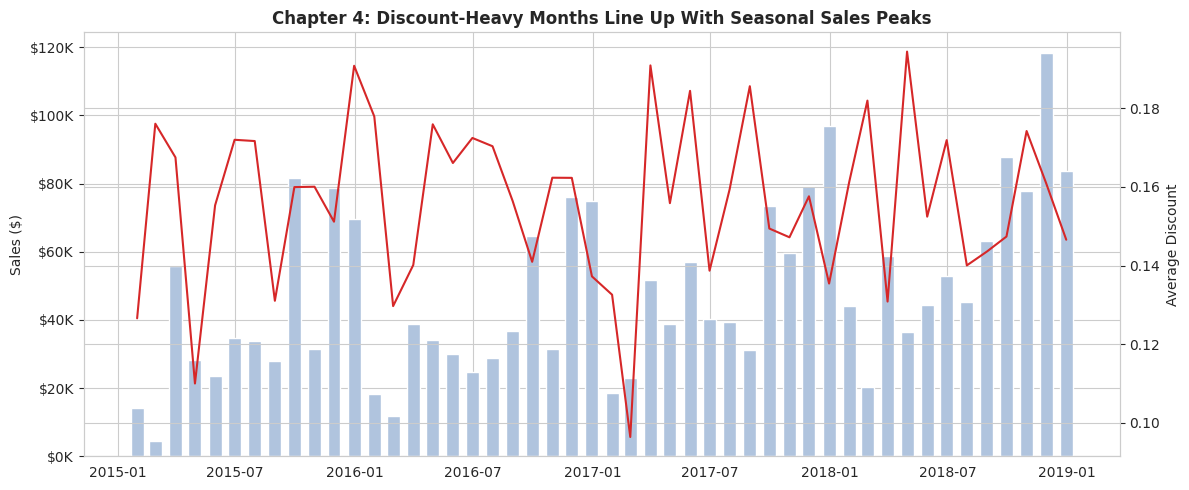

In [ ]:
monthly = df.set_index('Order Date').resample('ME')[['Sales','Discount']].agg({'Sales':'sum','Discount':'mean'})

fig, ax1 = plt.subplots(figsize=(12,5))
ax1.bar(monthly.index, monthly['Sales'], width=20, color='#B0C4DE', label='Sales')
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:,.0f}K'))
ax1.set_ylabel('Sales ($)')

ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly['Discount'], color='#d62728', linewidth=1.5, label='Avg Discount')
ax2.set_ylabel('Average Discount')

plt.title('Chapter 4: Discount-Heavy Months Line Up With Seasonal Sales Peaks', fontsize=12, fontweight='bold')
fig.tight_layout()
plt.savefig('story_ch4_seasonality.png', dpi=120)
plt.show()


**Narrative:** The year-end sales spikes that looked purely positive in Chapter 1 are, in
several months, accompanied by higher average discount levels — meaning some of that seasonal
revenue growth is coming at the cost of margin, tying the whole story back together.